# Лабораторная работа №2

Методом прогонки решить разностный аналог граничной задачи для уравнения $$y'' = \sin{x}$$
на промежутках $$0 < x < \pi$$
и $$-\frac{\pi}{2} < x < \frac{\pi}{2}$$  

Рассмотреть различные варианты граничных условий на функцию и её производную. Исследовать порядок сходимости.

# Начнем с аналитического решения

Благо, что уравнение не самое сложное, поэтому можно сразу определить общий вид неизвестной функции:
$$y'' = \sin{x} \Longrightarrow \int{y''dx} = \int{\sin{x} \ dx} \Longrightarrow y' = -\cos{x} + C_1 \Longrightarrow$$
$$\Longrightarrow \int{y'dx} = \int{(-\cos{x} + C_1) \ dx} \Longrightarrow y = -\sin{x} + C_1 \cdot x + C_2$$
$$C_1 , C_2 \in \mathbb{R}$$

**Граничная задача** - это дифференциальное уравнение вместе с условиями, заданными на границах области.  

Из курса уравнений математической физики известно, что граничные условия, к примеру, для отрезка $[a,b]$ могут быть следующих видов:  
$$Дирихле \ : \begin{cases} y(a) = A, \\ y(b) = B \end{cases}$$
$$Нейман \ : \begin{cases} y'(a) = A, \\ y'(b) = B \end{cases}$$
$$Смешанный \ : \begin{cases} y'(a) = A, \\ y(b) = B \end{cases}$$

**Разностный аналог** граничной задачи - это та же граничная задача, только с "приближенными значениями" производных, вычисленных по формулам, вместо самих производных.  

Я бы даже сказал так, говоря о цели лабораторной: нужно заменить дифференциальное уравнение системой линейных алгебраических уравнений, решить ее методом прогонки и исследовать точность полученного решения.

Посмотрим на семейство решений нашего дифференциального уравнения.

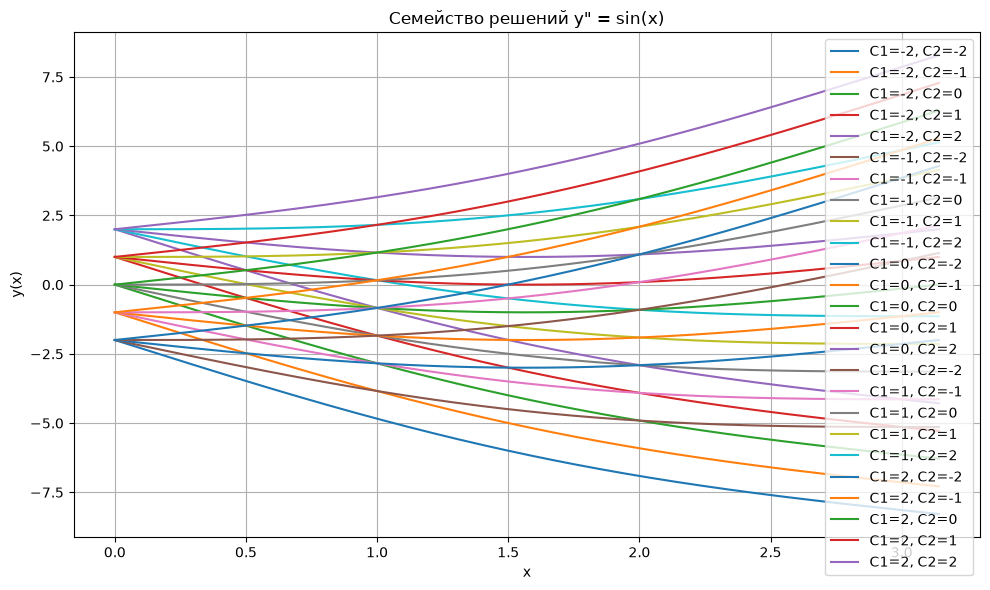

In [3]:
import matplotlib.pyplot as plt
import numpy as np

a = 0
b = 500

x = np.linspace(a, np.pi, b)

def y(c, C1, C2):
    return -np.sin(x) + C1 * x + C2

plt.figure(figsize=(10,6))

params = [-2, -1, 0, 1, 2]

for C1 in params:
    for C2 in params:
        plt.plot(x, y(x, C1, C2), label=f"C1={C1}, C2={C2}")

plt.xlabel('x')
plt.ylabel('y(x)')
plt.title('Семейство решений y" = sin(x)')
plt.grid()
plt.tight_layout()
plt.legend()
plt.show()

Ну посмотрели и посмотрели

С помощью интерполяционного полинома Лагранжа можно получить формулу второй производной на равномерной сетке ($h_i = h = const$): $$y''(x_i) \approx \frac{y(x_{i-1}) - 2 \cdot y(x_i) + y(x_{i+1})}{h^2}$$

Собственно, подставляем это в наше дифференциальное уравнение $y'' = \sin(x)$ и получаем: 
$$\begin{cases} y'' = \sin(x) \\ y''(x_i) \approx \frac{y(x_{i-1}) - 2 \cdot y(x_i) + y(x_{i+1})}{h^2}  \\ y(x_i) \approx u_i \end{cases} \Longrightarrow \frac{u_{i-1} - 2 \cdot u_i + u_{i+1}}{h^2} = \sin(x_i) \xRightarrow{\cdot h^2} u_{i-1} - 2 \cdot u_i + u_{i+1} = h^2 \cdot \sin(x_i)$$

Мы получили $u_{i-1} - 2 \cdot u_i + u_{i+1} = h^2 \cdot \sin(x_i)$, очевидно, что это соотношение у нас выполняется во всех узлах сетки (которую мы еще не задали...)

Так что давайте зафиксируем сразу тот самый отрезок $[a,b]$, на котором и будем работать с граничной задачей (в коде числа всегда можно будет потом поменять)

А еще сразу введем равномерную сетку: $$x_i = a + i \cdot h, \ \   h = \frac{b - a}{N}, \ \   i = 0, ..., N$$

Тогда получаем: $$\begin{cases}
u_0 - 2 \cdot u_1 + u_2 = h^2 \cdot \sin(x_1) \\
u_1 - 2 \cdot u_2 + u_3 = h^2 \cdot \sin(x_2) \\
u_2 - 2 \cdot u_3 + u_4 = h^2 \cdot \sin(x_3) \\
... \\
u_{N-2} - 2 \cdot u_{N-1} + u_{N} = h^2 \cdot \sin(x_{N-1}) \end{cases}$$

Вот и наша система линейных алгебраических уравнений.